# 09 · El método de la transformada inversa

Toda función de distribución es la distribución de alguna variable aleatoria, y una sola variable uniforme basta para construirla: $X=F^{-1}(U)$. Este cuaderno desarrolla la teoría, la ilustra con distribuciones discretas, continuas, singulares y mixtas, y la usa para muestrear.

**Contenido**

1. Funciones de distribución
2. La inversa generalizada y el teorema de simulación
3. Muestreo de la distribución exponencial
4. Histogramas con `matplotlib`
5. Funciones `lambda` y `map`
6. Validación con `scipy.stats`: gráfica cuantil–cuantil
7. Muestreo de otras distribuciones

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st

rng = np.random.default_rng(2026)

## 1. Funciones de distribución

Sea $X$ una variable aleatoria sobre $(\Omega,\mathcal F,\mathbb P)$, es decir, una función $X:\Omega\to\mathbb R$ tal que $(X\le x):=X^{-1}(-\infty,x]\in\mathcal F$ para todo $x\in\mathbb R$. Su **función de distribución** es

$$F(x):=\mathbb P(X\le x),\qquad x\in\mathbb R.$$

**Teorema 1.** Si $F$ es la función de distribución de una variable aleatoria, entonces

1. $0\le F(x)\le 1$ para toda $x$;
2. $F$ es no decreciente;
3. $\lim_{x\to-\infty}F(x)=0$ y $\lim_{x\to+\infty}F(x)=1$;
4. $F$ es continua por la derecha y tiene límites por la izquierda (*càdlàg*).

Además $\mathbb P(X=x)=F(x)-F(x^-)$: los saltos de $F$ son los átomos de $X$.

Cualquier función $F:\mathbb R\to\mathbb R$ con estas cuatro propiedades se llama **función de distribución**.

### Variable discreta

Una variable es **discreta** si toma a lo más una cantidad numerable de valores $k$, con $\sum_k\mathbb P(X=k)=1$. Entonces $F(x)=\sum_{k\le x}\mathbb P(X=k)$ es una función escalonada. Por ejemplo, con rango $\{-2,0,2,4,5\}$ y

$$\mathbb P(X=-2)=\mathbb P(X=0)=\mathbb P(X=4)=\mathbb P(X=5)=\tfrac16,\qquad \mathbb P(X=2)=\tfrac13,$$

$$F(x)=\begin{cases}0& x<-2\\ \frac16& -2\le x<0\\ \frac13& 0\le x<2\\ \frac23& 2\le x<4\\ \frac56&4\le x<5\\ 1& x\ge5.\end{cases}$$

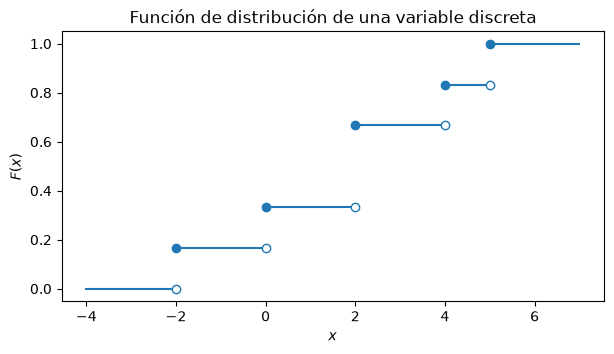

In [2]:
valores = np.array([-2, 0, 2, 4, 5])
pesos = np.array([1, 1, 2, 1, 1]) / 6
F_valores = np.cumsum(pesos)


def dibuja_escalonada(ax, valores, F_valores, xmin, xmax):
    bordes = np.r_[xmin, valores, xmax]
    niveles = np.r_[0, F_valores]
    for a, b, y in zip(bordes[:-1], bordes[1:], niveles):
        ax.plot([a, b], [y, y], color="tab:blue")
    ax.plot(valores, F_valores, "o", color="tab:blue")                       # valor en el salto
    ax.plot(valores, np.r_[0, F_valores[:-1]], "o", mfc="white", color="tab:blue")  # límite izquierdo


fig, ax = plt.subplots(figsize=(7, 3.5))
dibuja_escalonada(ax, valores, F_valores, -4, 7)
ax.set_title("Función de distribución de una variable discreta")
ax.set_xlabel("$x$")
ax.set_ylabel("$F(x)$")
plt.show()

### Variable absolutamente continua

$X$ es **absolutamente continua** si existe una **densidad** $f\ge0$ con $\int_{-\infty}^{\infty}f=1$ y

$$F(x)=\int_{-\infty}^x f(t)\,dt.$$

Por ejemplo, la distribución **logística** tiene $F(x)=\dfrac{1}{1+e^{-x}}$ y densidad $f(x)=F(x)(1-F(x))$.

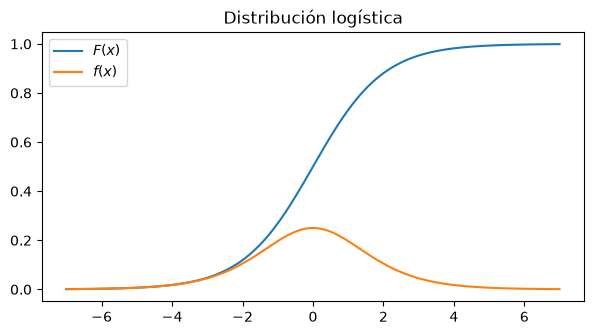

In [3]:
x = np.linspace(-7, 7, 400)
F = 1 / (1 + np.exp(-x))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(x, F, label="$F(x)$")
ax.plot(x, F * (1 - F), label="$f(x)$")
ax.set_title("Distribución logística")
ax.legend()
plt.show()

### Una distribución continua y singular: la escalera de Cantor

La función de Cantor $s:[0,1]\to[0,1]$ es el límite uniforme de las funciones $s_n$ definidas por $s_0(x)=x$ y

$$s_{n+1}(x)=\begin{cases}\frac12 s_n(3x)& 0\le x\le\frac13\\ \frac12& \frac13\le x\le\frac23\\ \frac12+\frac12 s_n(3x-2)& \frac23\le x\le1.\end{cases}$$

La función $F$ igual a $0$ en $(-\infty,0)$, a $s$ en $[0,1)$ y a $1$ en $[1,\infty)$ es una función de distribución. Es continua (no hay átomos), pero su derivada es $0$ en casi todo punto: no tiene densidad. Toda la masa vive en el conjunto de Cantor, que tiene medida de Lebesgue cero.

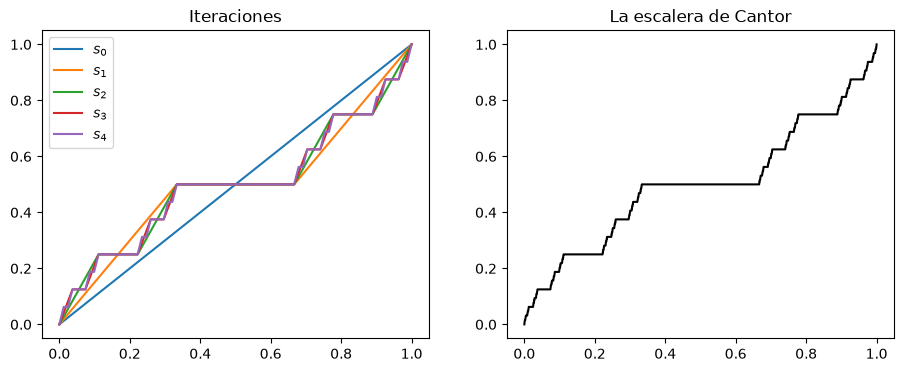

In [4]:
def cantor(x, n):
    x = np.asarray(x, dtype=float)
    if n == 0:
        return x
    return np.where(x <= 1 / 3, cantor(3 * x, n - 1) / 2,
           np.where(x <= 2 / 3, 0.5, 0.5 + cantor(np.clip(3 * x - 2, 0, 1), n - 1) / 2))


x = np.linspace(0, 1, 3000)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for n in range(5):
    axes[0].plot(x, cantor(x, n), label=f"$s_{n}$")
axes[0].legend()
axes[0].set_title("Iteraciones")
axes[1].plot(x, cantor(x, 12), color="k")
axes[1].set_title("La escalera de Cantor")
plt.show()

**Ejercicio.** Demuestra que $F$ satisface las propiedades del Teorema 1.

### Una distribución que no es discreta ni continua

$$F(x)=\begin{cases}\dfrac{1}{1+5e^{-2x/5}}& x<2\\[0.6em] \dfrac{1}{1+2e^{-3x/5}}& x\ge 2.\end{cases}$$

$F$ es creciente en cada tramo y en $x=2$ salta de $F(2^-)\approx0.31$ a $F(2)\approx0.62$: la variable tiene un átomo en $2$ y una parte con densidad.

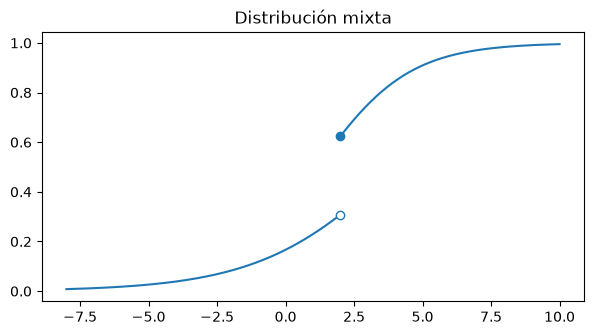

masa del átomo en 2: 0.3161


In [5]:
def F_mixta(x):
    x = np.asarray(x, dtype=float)
    return np.where(x < 2, 1 / (1 + 5 * np.exp(-2 * x / 5)), 1 / (1 + 2 * np.exp(-3 * x / 5)))

x1, x2 = np.linspace(-8, 2, 200, endpoint=False), np.linspace(2, 10, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(x1, F_mixta(x1), color="tab:blue")
ax.plot(x2, F_mixta(x2), color="tab:blue")
ax.plot([2], [F_mixta(1.999999)], "o", mfc="white", color="tab:blue")
ax.plot([2], [F_mixta(2)], "o", color="tab:blue")
ax.set_title("Distribución mixta")
plt.show()
print(f"masa del átomo en 2: {F_mixta(2) - F_mixta(2 - 1e-12):.4f}")

**Ejercicio.** Demuestra que esta $F$ es una función de distribución.

### Una pregunta importante

Dada una función de distribución $F$ cualquiera, ¿existen un espacio de probabilidad y una variable aleatoria $X$ cuya distribución sea $F$? La respuesta es sí, y la construcción es explícita.

## 2. La inversa generalizada y el teorema de simulación

La **inversa generalizada** (función cuantil) de una función de distribución $F$ es

$$F^{-1}(u)=\inf\{x\in\mathbb R:\ F(x)\ge u\},\qquad u\in(0,1).$$

Si $F$ es continua y estrictamente creciente, $F^{-1}$ es la inversa usual. En general, $F^{-1}$ recorre los saltos de $F$ con tramos constantes y salta sobre los tramos planos de $F$. Su propiedad fundamental, consecuencia de la continuidad por la derecha, es

$$F^{-1}(u)\le x\iff u\le F(x).$$

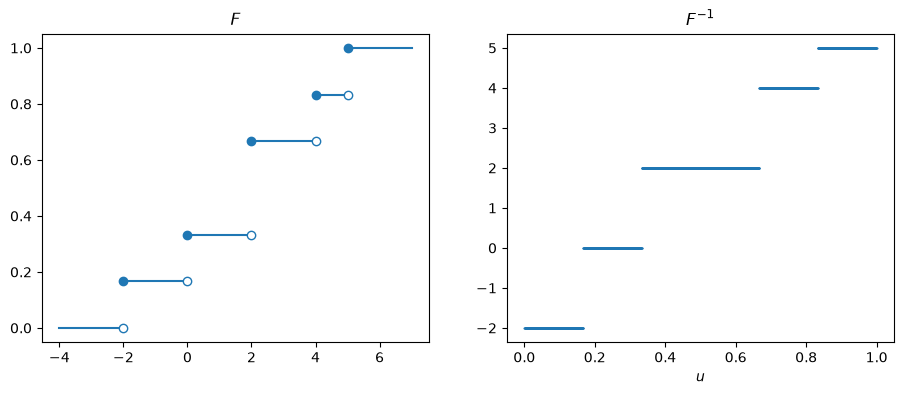

In [6]:
def cuantil_discreto(u, valores, F_valores):
    """Inversa generalizada de una F escalonada: el menor valor con F >= u."""
    return valores[np.searchsorted(F_valores, u, side="left")]

u = np.linspace(1e-4, 1 - 1e-4, 2000)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
dibuja_escalonada(axes[0], valores, F_valores, -4, 7)
axes[0].set_title("$F$")
axes[1].plot(u, cuantil_discreto(u, valores, F_valores), ".", ms=1)
axes[1].set_title("$F^{-1}$")
axes[1].set_xlabel("$u$")
plt.show()

Una referencia sobre la inversa generalizada: P. Embrechts y M. Hofert, [*A note on generalized inverses*](https://people.math.ethz.ch/~embrecht/ftp/generalized_inverse.pdf).

**Teorema 2.** Sea $F$ una función de distribución y $U$ una variable uniforme sobre $(0,1)$. Entonces $X=F^{-1}(U)$ tiene distribución $F$.

El espacio de probabilidad canónico es $\Omega=(0,1)$ con los borelianos y la medida de Lebesgue, y $U(\omega)=\omega$.

*Demostración.* Por la propiedad fundamental, $(X\le x)=(F^{-1}(U)\le x)=(U\le F(x))$, así que

$$\mathbb P(X\le x)=\mathbb P(U\le F(x))=F(x).\qquad\blacksquare$$

### Muestreo

Una **muestra aleatoria de tamaño $m$** de $F$ es una colección $x_1,\dots,x_m$ de realizaciones independientes de $X\sim F$. El teorema da el algoritmo:

1. generar $u_1,\dots,u_m$ uniformes independientes en $(0,1)$;
2. evaluar $x_i=F^{-1}(u_i)$.

Comprobamos con la variable discreta de arriba:

In [7]:
muestra = cuantil_discreto(rng.random(60_000), valores, F_valores)
vals, cuentas = np.unique(muestra, return_counts=True)
dict(zip(vals.tolist(), np.round(cuentas / len(muestra), 4).tolist())), dict(zip(valores.tolist(), np.round(pesos, 4).tolist()))

({-2: 0.1682, 0: 0.1685, 2: 0.3323, 4: 0.1663, 5: 0.1647},
 {-2: 0.1667, 0: 0.1667, 2: 0.3333, 4: 0.1667, 5: 0.1667})

## 3. Muestreo de la distribución exponencial

Si $X\sim\exp(\alpha)$ con $\alpha>0$, entonces

$$f_\alpha(x)=\alpha e^{-\alpha x}\mathbf 1_{\{x\ge0\}},\qquad F_\alpha(x)=(1-e^{-\alpha x})\mathbf 1_{\{x\ge0\}},\qquad F_\alpha^{-1}(u)=\frac1\alpha\ln\frac{1}{1-u}.$$

Como $1-U$ también es uniforme, $-\frac1\alpha\ln U$ tiene la misma ley.

In [8]:
def F_inv_exp(u, alpha):
    return np.log(1 / (1 - u)) / alpha

alpha = 1.0
u = rng.random(10)
print("u =", np.round(u, 4))
print("x =", np.round(F_inv_exp(u, alpha), 4))

u = [0.0653 0.1938 0.1997 0.3894 0.7004 0.9647 0.7174 0.0218 0.0519 0.1866]
x = [0.0676 0.2154 0.2228 0.4933 1.2053 3.3439 1.2638 0.022  0.0533 0.2065]


## 4. Histogramas con `matplotlib`

Un **histograma** de datos $S=\{x_1,\dots,x_m\}$ agrupa los datos en clases $I_1=[a_1,b_1),\dots,I_k=[a_k,b_k]$ con $a_1<b_1=a_2<\cdots<b_k$ y $S\subset[a_1,b_k]$. Hay tres tipos según la altura de cada barra:

- **frecuencias** $f_j=\#\{s\in S: s\in I_j\}$, con $\sum_j f_j=m$;
- **frecuencias relativas** $r_j=f_j/m$, con $\sum_j r_j=1$;
- **densidades** $d_j=r_j/(b_j-a_j)$, con $\sum_j(b_j-a_j)d_j=1$: el área total es $1$.

El histograma de densidad es el que se compara con una densidad de probabilidad. Si todas las clases tienen ancho $1$, coincide con el de frecuencias relativas. Por ejemplo, con los $16$ datos

In [9]:
datos = np.array([0.5, 1.2, 1.2, 1.5, 1.7, 2.0, 2.2, 2.5, 2.5, 2.8, 3.1, 3.3, 3.3, 4.2, 4.6, 5.2])
f, bordes = np.histogram(datos, bins=np.arange(0, 7))
print("frecuencias:", f, "\nrelativas:  ", np.round(f / len(datos), 3), "\ndensidades: ", np.round(f / len(datos) / np.diff(bordes), 3))

frecuencias: [1 4 5 3 2 1] 
relativas:   [0.062 0.25  0.312 0.188 0.125 0.062] 
densidades:  [0.062 0.25  0.312 0.188 0.125 0.062]


`plt.hist` devuelve la terna `(n, bins, patches)`:

- `n`: las alturas de las barras;
- `bins`: los bordes de las clases;
- `patches`: los rectángulos dibujados, útiles para cambiar su apariencia.

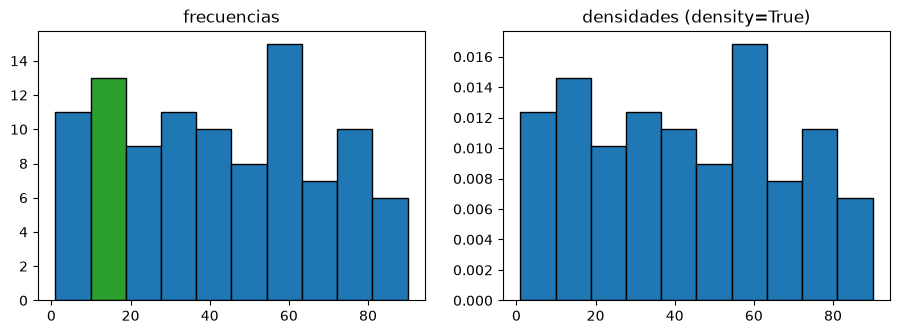

Σ n = 100.0
densidades a mano iguales a density=True: True


In [10]:
x = rng.integers(1, 91, size=100)   # 100 enteros entre 1 y 90

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
n, bins, patches = axes[0].hist(x, bins=10, edgecolor="black")
patches[1].set_facecolor("tab:green")
axes[0].set_title("frecuencias")
d, _, _ = axes[1].hist(x, bins=10, edgecolor="black", density=True)
axes[1].set_title("densidades (density=True)")
plt.show()

print("Σ n =", n.sum())
print("densidades a mano iguales a density=True:", np.allclose(n / len(x) / np.diff(bins), d))

Ahora el histograma de densidad de una muestra exponencial junto con la densidad teórica:

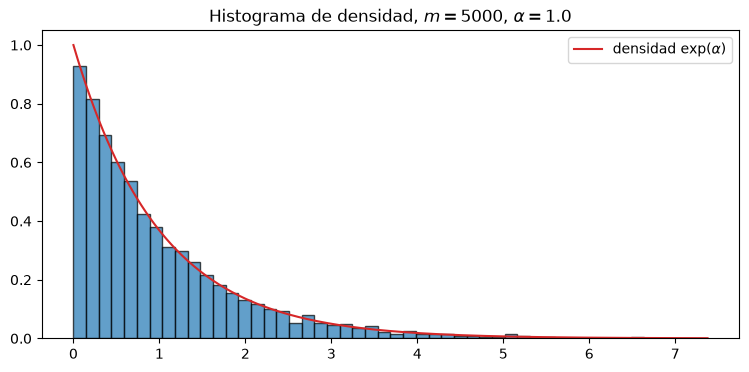

In [11]:
m = 5000
x = F_inv_exp(rng.random(m), alpha)

fig, ax = plt.subplots(figsize=(9, 4))
n, bins, _ = ax.hist(x, bins=50, density=True, edgecolor="black", alpha=0.7)
t = np.linspace(0, bins[-1], 300)
ax.plot(t, alpha * np.exp(-alpha * t), color="tab:red", label=r"densidad $\exp(\alpha)$")
ax.set_title(rf"Histograma de densidad, $m={m}$, $\alpha={alpha}$")
ax.legend()
plt.show()

## 5. Funciones `lambda` y `map`

Una **función lambda** es una función anónima de una sola expresión: `lambda argumentos: expresión`. Es útil para funciones cortas que se usan una sola vez, por ejemplo como argumento de otra función.

In [12]:
suma10 = lambda a: a + 10
producto = lambda a, b: a * b
print(suma10(0), producto(3, 4), (lambda a, b: a * b)(4, 8))

10 12 32


Una función puede devolver una lambda (una **función de orden superior**):

In [13]:
def multiplicador(n):
    return lambda a: a * n

doble, triple = multiplicador(2), multiplicador(3)
doble(11), triple(11)

(22, 33)

`map(f, iterable, ...)` aplica `f` a cada elemento (o a elementos correspondientes de varios iterables) y devuelve un iterador perezoso; `list` lo materializa.

In [14]:
print(list(map(lambda n: n + n, (1, 2, 3, 4))))
print(list(map(lambda x, y: x + y, [1, 2, 3], [4, 5, 6])))

[2, 4, 6, 8]
[5, 7, 9]


## 6. Validación con `scipy.stats`: gráfica cuantil–cuantil

Repetimos el muestreo exponencial con `scipy.stats.uniform`, una lambda y `map` (como en J. Unpingco, *Python for Probability, Statistics, and Machine Learning*). Para comprobar que el método es correcto comparamos los cuantiles empíricos con los de la distribución exponencial de `scipy.stats`: si los puntos siguen la diagonal, las leyes coinciden.

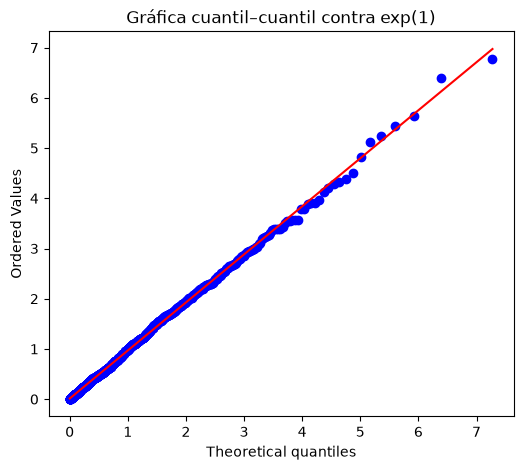

prueba de Kolmogorov–Smirnov: KstestResult(statistic=np.float64(0.02832640163745337), pvalue=np.float64(0.3913664726130901), statistic_location=np.float64(0.6418337232645062), statistic_sign=np.int8(1))


In [15]:
m = 1000
U = st.uniform(0, 1)
F_inv = lambda u: np.log(1 / (1 - u)) / alpha
v = np.fromiter(map(F_inv, U.rvs(m, random_state=rng)), dtype=float)

fig, ax = plt.subplots(figsize=(6, 5))
st.probplot(v, dist=st.expon(scale=1 / alpha), plot=ax)
ax.set_title("Gráfica cuantil–cuantil contra exp(1)")
plt.show()
print("prueba de Kolmogorov–Smirnov:", st.kstest(v, st.expon(scale=1 / alpha).cdf))

## 7. Muestreo de otras distribuciones

### Cauchy, Weibull y la distribución mixta

| ley | $F(x)$ | $F^{-1}(u)$ |
|---|---|---|
| Cauchy | $\frac12+\frac1\pi\arctan x$ | $\tan\big(\pi(u-\frac12)\big)$ |
| Weibull$(k,\lambda)$ | $1-e^{-(x/\lambda)^k}$ | $\lambda(-\ln(1-u))^{1/k}$ |
| logística | $\frac1{1+e^{-x}}$ | $\ln\frac{u}{1-u}$ |

Para la distribución mixta no hay fórmula cerrada en un tramo, pero la inversa generalizada se calcula numéricamente por bisección, porque $F$ es monótona.

proporción de la muestra en x = 2: 0.3161


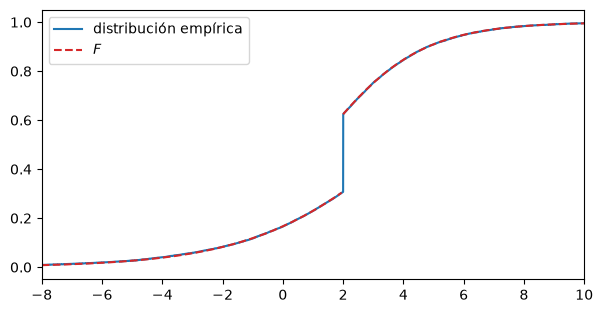

In [16]:
def cuantil_numerico(F, u, a=-60.0, b=60.0, iteraciones=60):
    """Inversa generalizada por bisección: menor x con F(x) >= u."""
    a = np.full_like(u, a)
    b = np.full_like(u, b)
    for _ in range(iteraciones):
        c = (a + b) / 2
        arriba = F(c) >= u
        b = np.where(arriba, c, b)
        a = np.where(arriba, a, c)
    return b

x_mixta = cuantil_numerico(F_mixta, rng.random(20_000))
t = np.sort(x_mixta)
print(f"proporción de la muestra en x = 2: {np.mean(np.isclose(x_mixta, 2)):.4f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(t, np.arange(1, len(t) + 1) / len(t), where="post", label="distribución empírica")
ax.plot(x1, F_mixta(x1), "--", color="tab:red", label="$F$")
ax.plot(x2, F_mixta(x2), "--", color="tab:red")
ax.set_xlim(-8, 10)
ax.legend()
plt.show()

### La distribución de Cantor

La inversa generalizada de la escalera de Cantor se describe con dígitos: si $U=\sum_{k\ge1}b_k2^{-k}$ es la expansión binaria de $U$, entonces $F^{-1}(U)=\sum_{k\ge1}2b_k3^{-k}$. Como los dígitos binarios de una uniforme son Bernoulli$(1/2)$ independientes, una variable de Cantor es $X=\sum_k 2b_k3^{-k}$ con $b_k$ independientes.

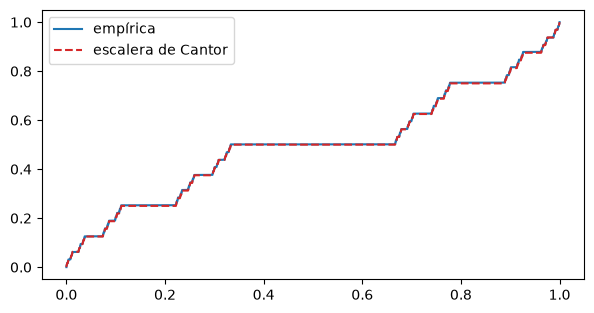

E[X] = 0.4984 (teórico 1/2),  Var(X) = 0.1248 (teórico 1/8)


In [17]:
b = rng.integers(0, 2, size=(50_000, 40))
X_cantor = (2 * b * 3.0 ** -np.arange(1, 41)).sum(axis=1)
t = np.sort(X_cantor)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(t, np.arange(1, len(t) + 1) / len(t), where="post", label="empírica")
xx = np.linspace(0, 1, 2000)
ax.plot(xx, cantor(xx, 12), "--", color="tab:red", label="escalera de Cantor")
ax.legend()
plt.show()
print(f"E[X] = {X_cantor.mean():.4f} (teórico 1/2),  Var(X) = {X_cantor.var():.4f} (teórico 1/8)")

### Muestreo normal

La función de distribución normal no tiene inversa elemental; `scipy.stats.norm.ppf` la evalúa numéricamente. En la práctica se usa `rng.normal`, o el método de Box–Muller del cuaderno 13.

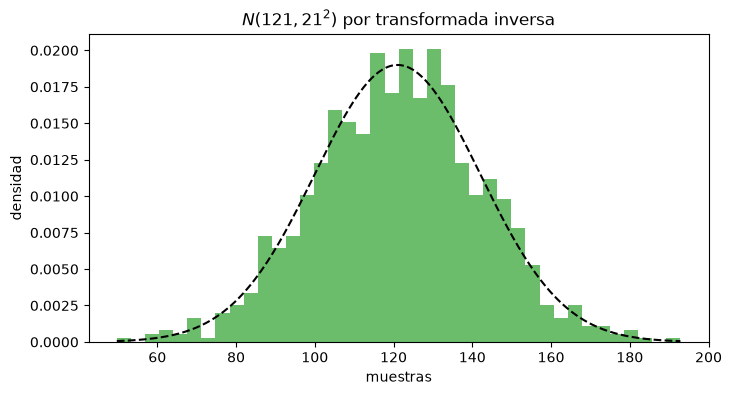

In [18]:
mu, sigma = 121, 21
x = mu + sigma * st.norm.ppf(rng.random(1000))

fig, ax = plt.subplots(figsize=(8, 4))
n, bins, _ = ax.hist(x, bins=40, density=True, color="tab:green", alpha=0.7)
t = np.linspace(bins[0], bins[-1], 300)
ax.plot(t, st.norm.pdf(t, mu, sigma), "--", color="black")
ax.set_xlabel("muestras")
ax.set_ylabel("densidad")
ax.set_title(rf"$N({mu}, {sigma}^2)$ por transformada inversa")
plt.show()

## Ejercicios

1. Muestrea la distribución de Weibull con $k=2$, $\lambda=1$ y compara el histograma con su densidad.
2. Verifica numéricamente que la escalera de Cantor $s$ satisface $s(x/3)=s(x)/2$ y $s(1-x)=1-s(x)$.
3. Demuestra la propiedad $F^{-1}(u)\le x\iff u\le F(x)$ usando la continuidad por la derecha de $F$.